# 04 — User Taste Clustering with K-Means

**Purpose:** Explore whether latent user representations from collaborative filtering form useful clusters.

K-Means is unsupervised: cluster IDs are arbitrary labels, not quality grades or fixed personality types.

## 1. Build user latent factors

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# Works when launched from the Spectra root or from the notebooks folder.
if not (PROJECT_ROOT / "datasets" / "ml-1m").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "datasets" / "ml-1m"

movies = pd.read_csv(
    DATA_DIR / "movies.dat", sep="::", engine="python",
    names=["movie_id", "title", "genres"], encoding="latin-1"
)
ratings = pd.read_csv(
    DATA_DIR / "ratings.dat", sep="::", engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"], encoding="latin-1"
)
users = pd.read_csv(
    DATA_DIR / "users.dat", sep="::", engine="python",
    names=["user_id", "gender", "age", "occupation", "zip_code"], encoding="latin-1"
)
print(f"Movies: {len(movies):,} | Ratings: {len(ratings):,} | Users: {len(users):,}")

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

user_item = ratings.pivot_table(
    index="user_id", columns="movie_id", values="rating", fill_value=0
)
# Dense conversion is manageable for MovieLens 1M but avoid this approach for 32M.
R = csr_matrix(user_item.to_numpy(dtype=np.float32))
svd = TruncatedSVD(n_components=50, n_iter=7, random_state=42)
user_factors = svd.fit_transform(R)
print("User-factor matrix:", user_factors.shape)

Movies: 3,883 | Ratings: 1,000,209 | Users: 6,040
User-factor matrix: (6040, 50)


## 2. Select cluster count using inertia and silhouette sample

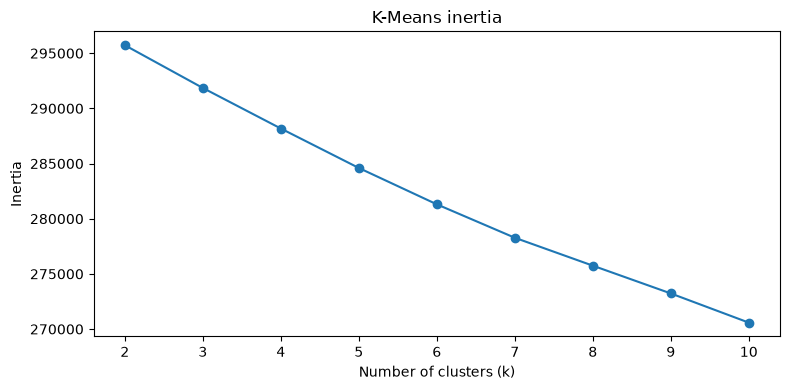

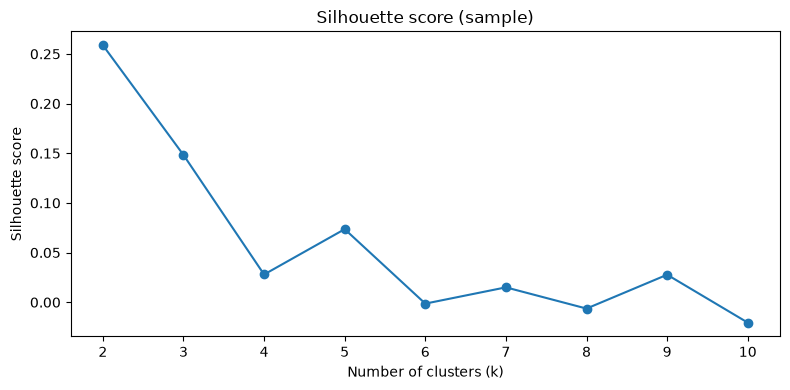

In [2]:
scaler = StandardScaler()
X = scaler.fit_transform(user_factors)

candidate_k = range(2, 11)
inertias, silhouettes = [], []
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X), size=min(5000, len(X)), replace=False)
for k in candidate_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X[sample_idx], labels[sample_idx]))

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(list(candidate_k), inertias, marker="o")
ax.set_title("K-Means inertia")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(list(candidate_k), silhouettes, marker="o")
ax.set_title("Silhouette score (sample)")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

## 3. Fit the selected 8-cluster configuration

In [3]:
N_CLUSTERS = 8  # Match the current Spectra training configuration for comparison.
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

clustered_users = pd.DataFrame({
    "user_id": user_item.index,
    "cluster": labels
})
display(clustered_users["cluster"].value_counts().sort_index().to_frame("users"))
print("Silhouette (sample):", silhouette_score(X[sample_idx], labels[sample_idx]))

,users
cluster,
0,180
1,789
2,490
3,564
4,394
5,427
6,2811
7,385


Silhouette (sample): -0.006356044672429562


## 4. Profile clusters by their most-liked genres

In [4]:
user_genres = ratings.merge(movies[["movie_id","genres"]], on="movie_id")
user_genres["genre"] = user_genres.genres.str.split("|")
user_genres = user_genres.explode("genre")
user_genres = user_genres.merge(clustered_users, on="user_id")

genre_profile = (user_genres[user_genres.rating >= 4]
                 .groupby(["cluster","genre"]).size()
                 .rename("high_ratings").reset_index())
for cluster_id in sorted(clustered_users.cluster.unique()):
    top_genres = (genre_profile[genre_profile.cluster == cluster_id]
                  .nlargest(5, "high_ratings"))
    print(f"Cluster {cluster_id}")
    display(top_genres[["genre","high_ratings"]])

Cluster 0


,genre,high_ratings
7,Drama,28290
4,Comedy,17754
15,Thriller,9623
0,Action,8856
13,Romance,8279


Cluster 1


,genre,high_ratings
18,Action,27869
32,Sci-Fi,20440
25,Drama,20147
22,Comedy,16377
33,Thriller,15852


Cluster 2


,genre,high_ratings
40,Comedy,24587
43,Drama,20901
36,Action,12077
51,Thriller,9580
50,Sci-Fi,8494


... (6 outputs left out)

Cluster 6


,genre,high_ratings
115,Drama,53802
112,Comedy,46030
108,Action,34046
123,Thriller,27940
122,Sci-Fi,18452


Cluster 7


,genre,high_ratings
130,Comedy,40972
133,Drama,37662
126,Action,26854
141,Thriller,18863
139,Romance,14385


## 5. Interpretation

Use cluster profiles to describe broad rating tendencies, not to label individuals. Compare cluster sizes and genre distributions. A silhouette score alone does not establish that clusters are useful to end users.